<a href="https://colab.research.google.com/github/sarbanibhadra/Binary_symptom_indicators_clinical/blob/main/MLAssignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Problem Statement: **
### Design a machine learning pipeline that is not only accurate but clinically interpretable and robust.
Modern healthcare screening systems often rely on binary symptom indicators
rather than continuous clinical measurements. Such data presents unique
challenges in modeling due to:
• Lack of numerical gradients
• High feature interdependence
• Interpretability requirements
You are provided with a symptom-based patient dataset, where each record
corresponds to an individual evaluated for a potential metabolic disorder.
Your objective is to design a machine learning pipeline that is not only accurate
but clinically interpretable and robust.

## **Q1. Data Understanding & Audit**
a. Load the dataset and perform a schema validation check:
* Data types
* Unique value distributions
* Class balance

b. Identify:
* Whether features are ordinal, nominal, or binary
* Any inconsistencies in encoding

c. Write a short note:
Why is this dataset not suitable for naive linear assumptions?

In [72]:
#********************************************************************
# Prepare setup and import libraries
#********************************************************************
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [73]:
#********************************************************************
# Establish connecion with Google drive to fetch dada
#********************************************************************
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [74]:
#********************************************************************
# Checking access to Google drive
#********************************************************************
!ls "/content/drive/MyDrive/ML/Assignment1/"

 MLAssignment1.ipynb		   'Problem statement 4.pdf'   PS4.xlsx
 ML_Project_Timeline_Tracker.xlsx   PS4Old.xlsx


In [75]:
#************************************************************************
# Load data from Google drive and check its datatypes and elements inside
#************************************************************************
df = pd.read_excel('/content/drive/MyDrive/ML/Assignment1/PS4.xlsx')
print("**************************")
print("Description of the dataset")
print("**************************")
print(df.describe())
print("*************************************")
print("Datatype information about dataset")
print("*************************************")
print(df.info())
print("*****************************************")
print("Exapmle of the elements in the dataset")
print("*****************************************")
print(df.head())
df.shape

**************************
Description of the dataset
**************************
              Age
count  520.000000
mean    48.028846
std     12.151466
min     16.000000
25%     39.000000
50%     47.500000
75%     57.000000
max     90.000000
*************************************
Datatype information about dataset
*************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching 

(520, 17)

In [76]:
#********************************************************************
# Check unique value distributions in each feature in the dataset
#********************************************************************
for col in df.columns:
    print(col, df[col].unique())

Age [40 58 41 45 60 55 57 66 67 70 44 38 35 61 54 43 62 39 48 32 42 52 53 37
 49 63 30 50 46 36 51 59 65 25 47 28 68 56 31 85 90 72 69 79 34 16 33 64
 27 29 26]
Gender ['Male' 'Female']
Polyuria ['No' 'Yes']
Polydipsia ['Yes' 'No']
sudden weight loss ['No' 'Yes']
weakness ['Yes' 'No']
Polyphagia ['No' 'Yes']
Genital thrush ['No' 'Yes']
visual blurring ['No' 'Yes']
Itching ['Yes' 'No']
Irritability ['No' 'Yes']
delayed healing ['Yes' 'No']
partial paresis ['No' 'Yes']
muscle stiffness ['Yes' 'No']
Alopecia ['Yes' 'No']
Obesity ['Yes' 'No']
class ['Positive' 'Negative']


In [77]:
#********************************************************************
# Check unique value distributions in each feature in the dataset
#********************************************************************
def schema_check(df):
    report = {}

    for col in df.columns:
        report[col] = {
            "dtype": str(df[col].dtype),
            "n_unique": df[col].nunique(),
            "unique_values_sample": df[col].unique()

        }

    return pd.DataFrame(report).T

schema_report = schema_check(df)
print(schema_report)

                     dtype n_unique  \
Age                  int64       51   
Gender              object        2   
Polyuria            object        2   
Polydipsia          object        2   
sudden weight loss  object        2   
weakness            object        2   
Polyphagia          object        2   
Genital thrush      object        2   
visual blurring     object        2   
Itching             object        2   
Irritability        object        2   
delayed healing     object        2   
partial paresis     object        2   
muscle stiffness    object        2   
Alopecia            object        2   
Obesity             object        2   
class               object        2   

                                                 unique_values_sample  
Age                 [40, 58, 41, 45, 60, 55, 57, 66, 67, 70, 44, 3...  
Gender                                                 [Male, Female]  
Polyuria                                                    [No, Yes]  
Polydipsi

## **Key observations:**


---



1.   patient_age contains impossible values: Negative ages: -25, -19, -1; Unrealistic values: 107, 109; Values like 0, 2, 3 (infants?)-unlikely for metabolic screening.
2.   sex column contains erronious data ['Male', 'Female', 79, 40, 27, 108, ...]
3.   Binary symptom columns contain random data:
Polyuria -
['No', 'Yes', 9.5, 15.5, 32.5, 48.5 ...];
sudden_weight loss -
['No', 'Yes', 'partly cloudy', 'overcast'];
Itching -
['Yes', 'No', 'mountain', 'coastal']



In [78]:
#********************************************************************
# Validating each column
#********************************************************************
# 1. Validate patient_age
df = df[(df['Age']>=0) & (df['Age']<100)]
df.info()
df['Age'].unique()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16  class               520 no

(520, 17)

In [79]:
# 2. Validate sex
# Among the list of unique elements in the df['sex'] columns only valid elements are 'Male' and 'Female'.
valid_sex = ['Male', 'Female']
df = df[df['Gender'].isin(valid_sex)]
df.info()
df['Gender'].unique()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16  class               520 no

(520, 17)

In [80]:
# Rest of the columns are binary symptom columns with valid entries are 'Yes' or 'No'
valid_binary = ['Yes', 'No']
for col in df.columns:
  if col not in ['patient_id', 'Age', 'Gender', 'class']:
    df = df[df[col].isin(valid_binary)]
    print(df[col].unique())
df.info()
df.shape

['No' 'Yes']
['Yes' 'No']
['No' 'Yes']
['Yes' 'No']
['No' 'Yes']
['No' 'Yes']
['No' 'Yes']
['Yes' 'No']
['No' 'Yes']
['Yes' 'No']
['No' 'Yes']
['Yes' 'No']
['Yes' 'No']
['Yes' 'No']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    

(520, 17)

In [81]:
# ************************
# Standardised encoding
# ************************
# Encode Gender
df['Gender'] = df['Gender'].replace({'Male': 1, 'Female': 0})

# Encode target variable 'class'
df['class'] = df['class'].replace({'Positive': 1, 'Negative': 0})

# Encode binary symptom columns
binary_data = {'Yes': 1, 'No': 0}
for col in df.columns:
  # Exclude 'Age', 'Gender', and 'class' as they are already handled or are not binary 'Yes'/'No'
  if col not in ['Age', 'Gender', 'class']:
    df[col] = df[col].replace(binary_data)

print(df.head())
print(df.shape)

   Age  Gender  Polyuria  Polydipsia  sudden weight loss  weakness  \
0   40       1         0           1                   0         1   
1   58       1         0           0                   0         1   
2   41       1         1           0                   0         1   
3   45       1         0           0                   1         1   
4   60       1         1           1                   1         1   

   Polyphagia  Genital thrush  visual blurring  Itching  Irritability  \
0           0               0                0        1             0   
1           0               0                1        0             0   
2           1               0                0        1             0   
3           1               1                0        1             0   
4           1               0                1        1             1   

   delayed healing  partial paresis  muscle stiffness  Alopecia  Obesity  \
0                1                0                 1         1 

/tmp/ipykernel_6499/2602485649.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Gender'] = df['Gender'].replace({'Male': 1, 'Female': 0})
/tmp/ipykernel_6499/2602485649.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['class'] = df['class'].replace({'Positive': 1, 'Negative': 0})
/tmp/ipykernel_6499/2602485649.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the fut

## **Q2. Exploratory Analysis with Insight Generation**

### **a. Univariate and Bivariate Visualization & Target-wise Feature Behavior**

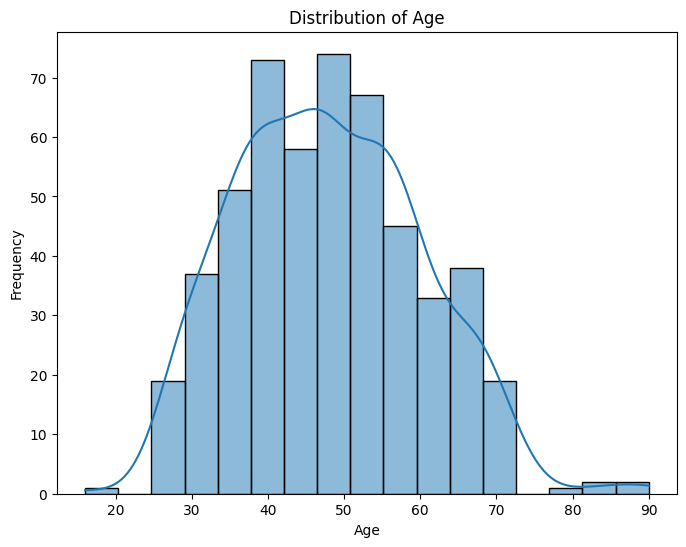

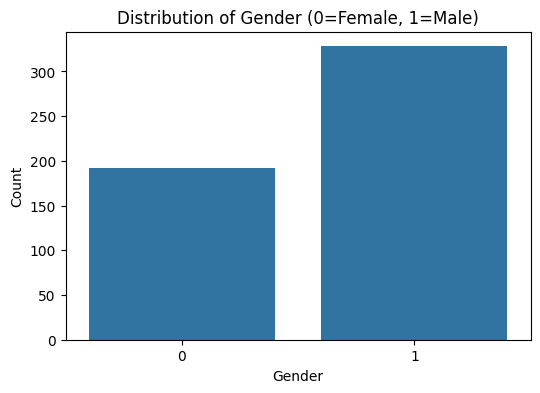

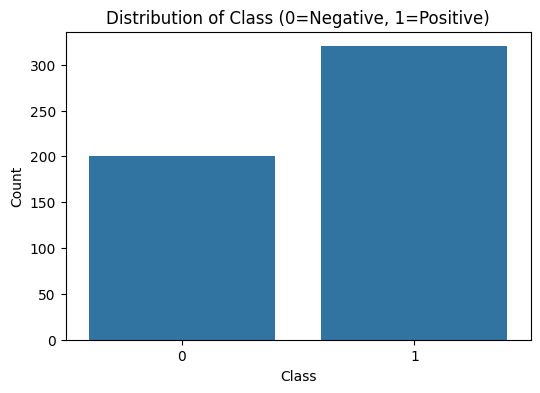

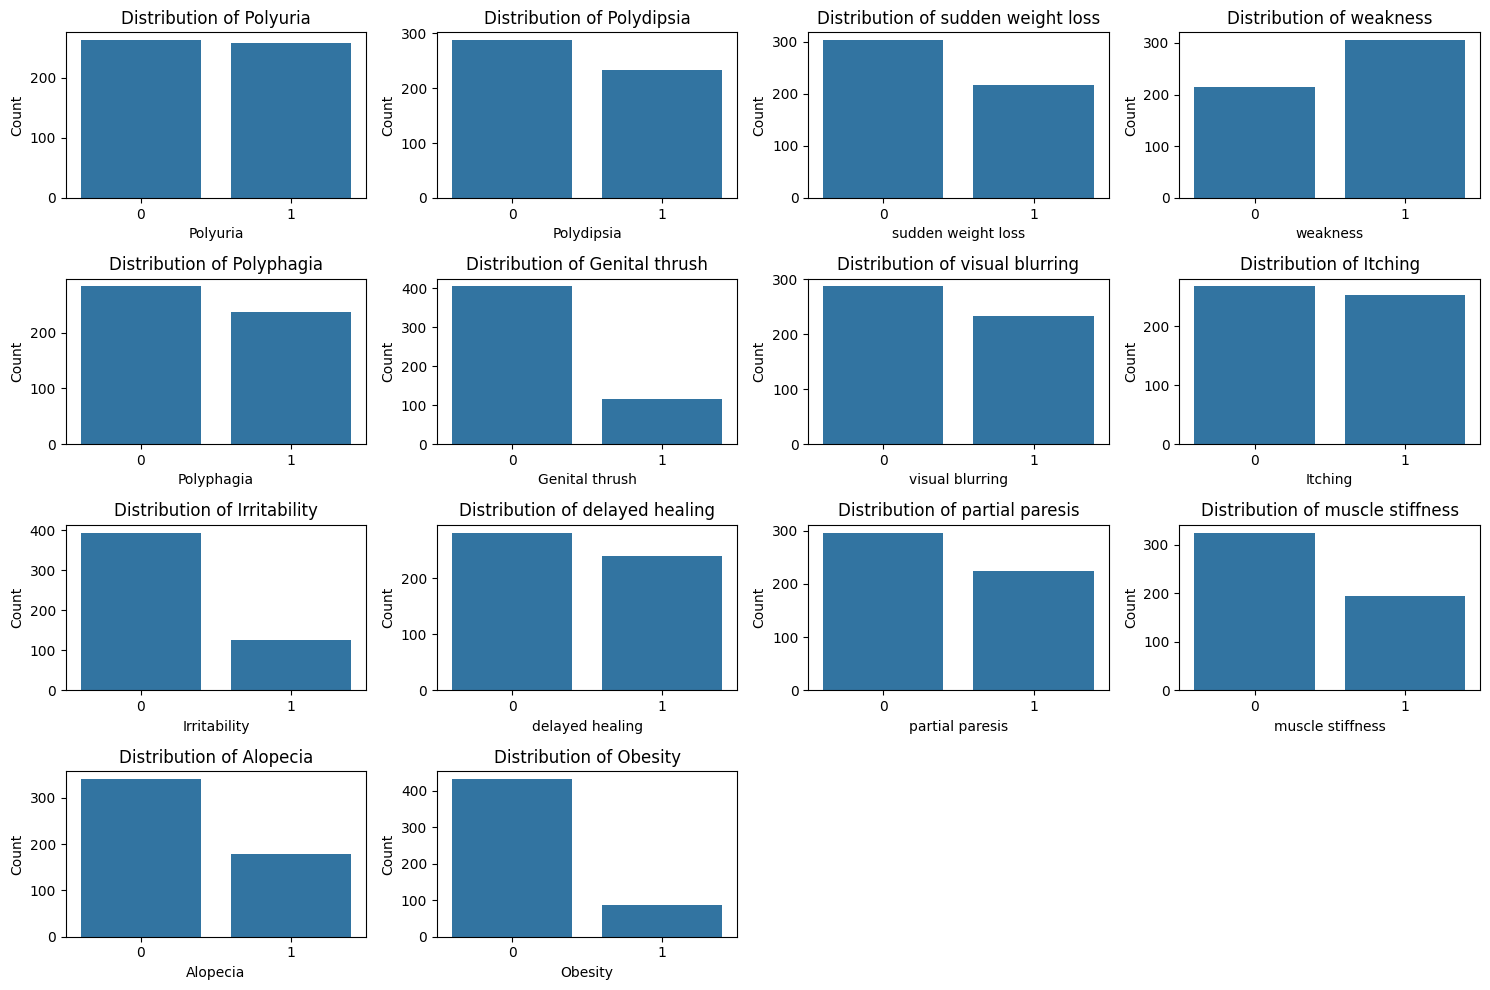

In [82]:
# Univariate Analysis for Age
plt.figure(figsize=(8, 6))
sns.histplot(df['Age'], kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# Univariate Analysis for Gender
plt.figure(figsize=(6, 4))
sns.countplot(x='Gender', data=df)
plt.title('Distribution of Gender (0=Female, 1=Male)')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# Univariate Analysis for Target Variable 'class'
plt.figure(figsize=(6, 4))
sns.countplot(x='class', data=df)
plt.title('Distribution of Class (0=Negative, 1=Positive)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Univariate Analysis for Binary Symptom Features
binary_cols = [col for col in df.columns if col not in ['Age', 'Gender', 'class']]

plt.figure(figsize=(15, 10))
for i, col in enumerate(binary_cols):
    plt.subplot(4, 4, i + 1) # Adjust subplot grid as needed
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
plt.tight_layout()
plt.show()


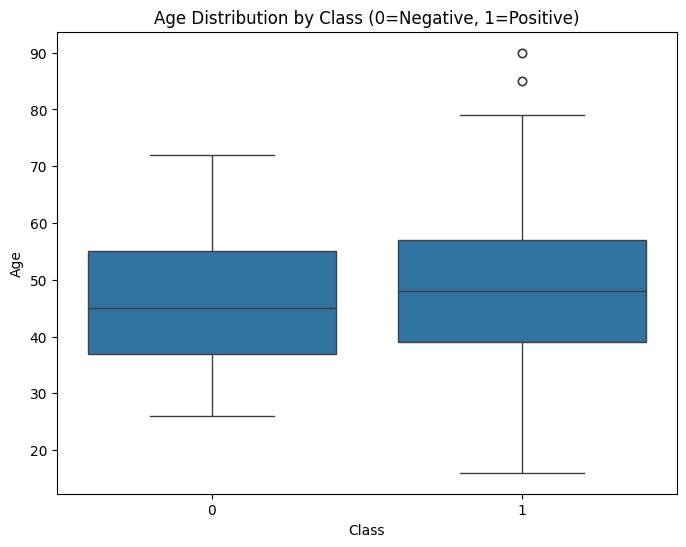

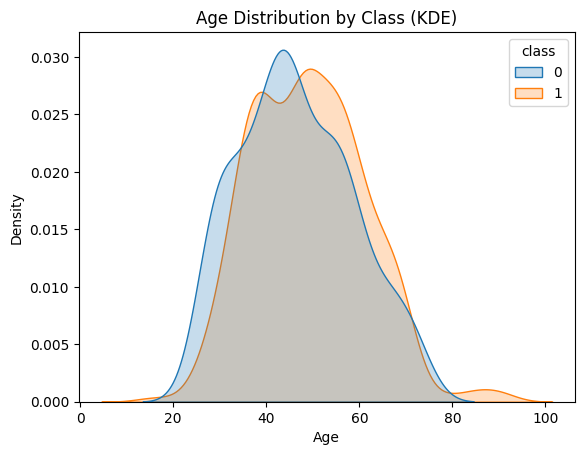

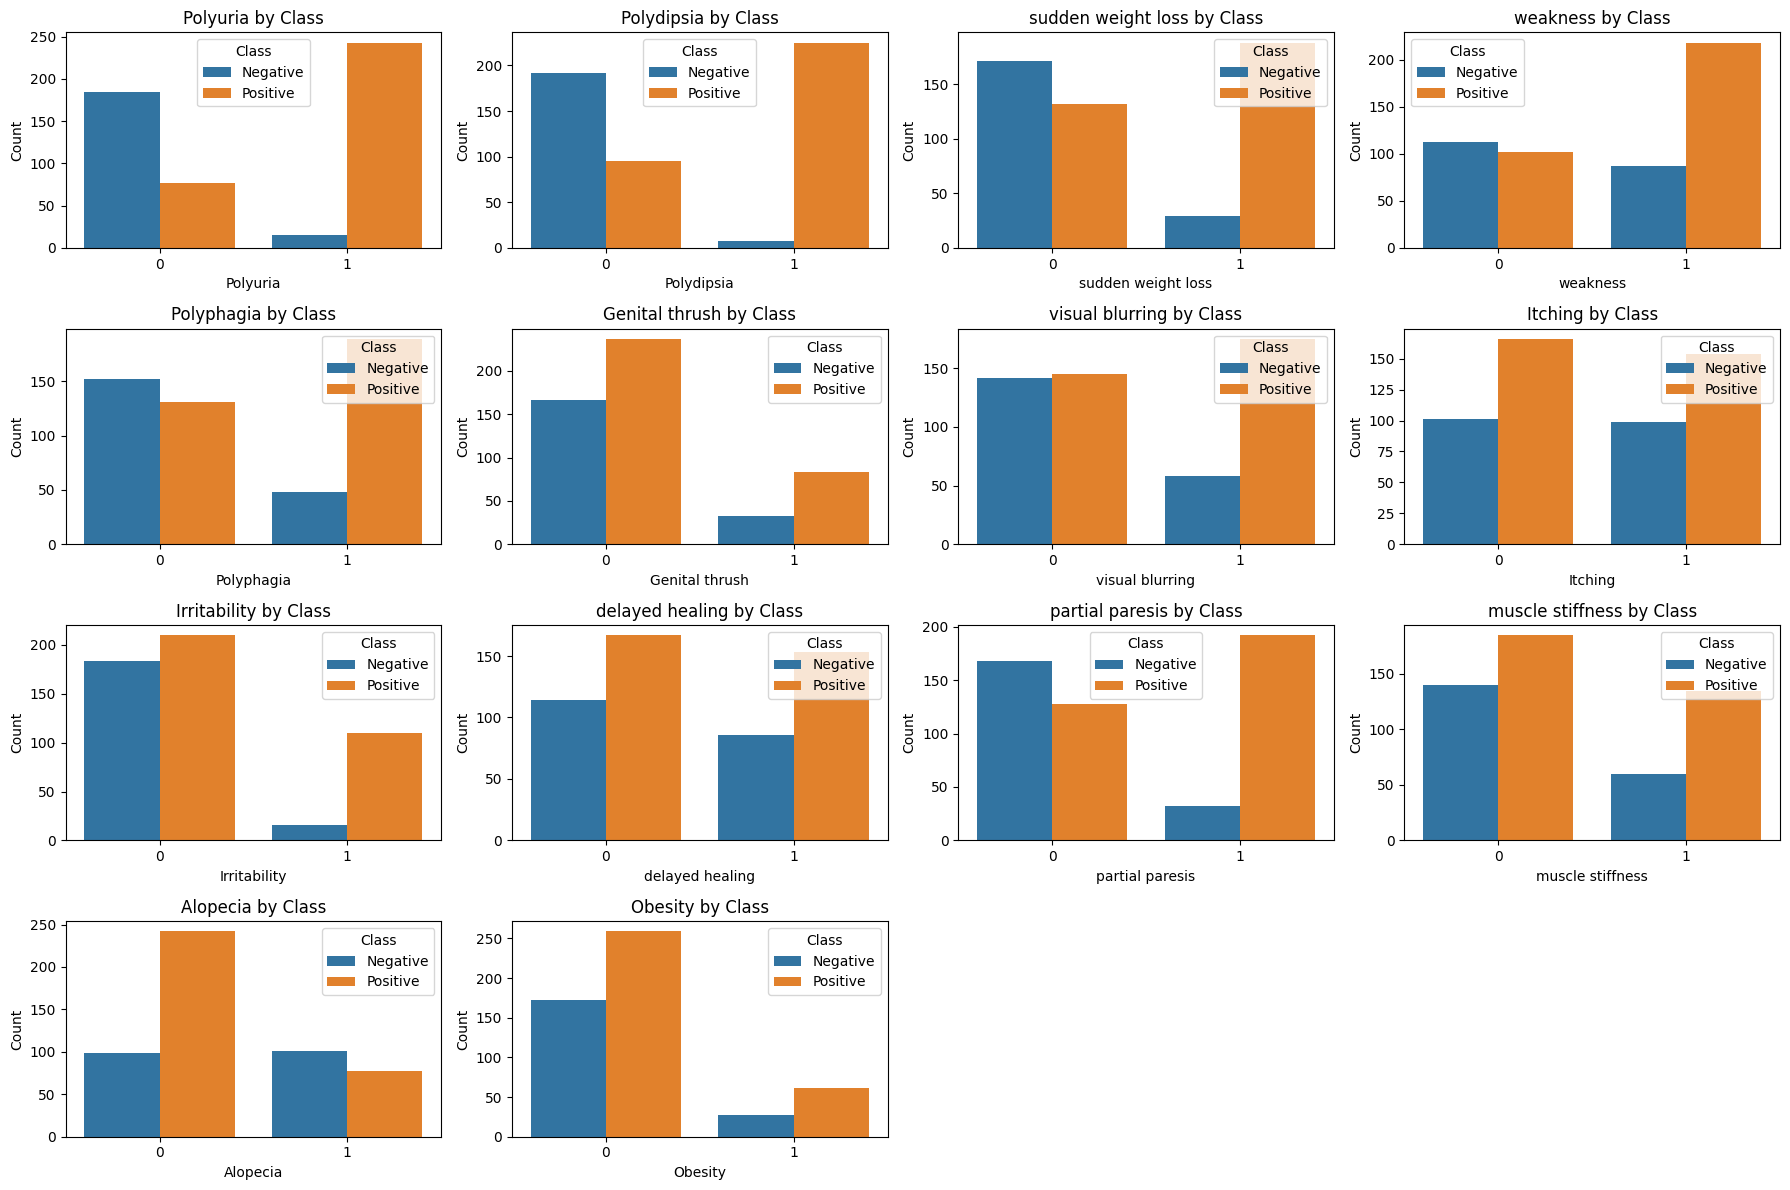

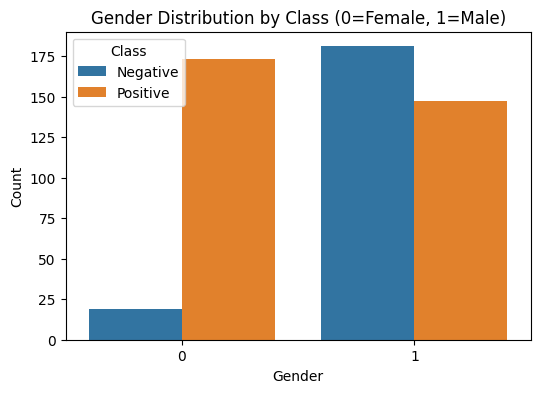

In [83]:
# Bivariate Analysis: Age vs. Class
plt.figure(figsize=(8, 6))
sns.boxplot(x='class', y='Age', data=df)
plt.title('Age Distribution by Class (0=Negative, 1=Positive)')
plt.xlabel('Class')
plt.ylabel('Age')
plt.show()

sns.kdeplot(data=df, x='Age', hue='class', fill=True, common_norm=False)
plt.title('Age Distribution by Class (KDE)')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

# Bivariate Analysis: Binary Symptoms vs. Class
plt.figure(figsize=(18, 12))
for i, col in enumerate(binary_cols):
    plt.subplot(4, 4, i + 1) # Adjust subplot grid as needed
    sns.countplot(x=col, hue='class', data=df)
    plt.title(f'{col} by Class')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.legend(title='Class', labels=['Negative', 'Positive'])
plt.tight_layout()
plt.show()

# Bivariate Analysis: Gender vs. Class
plt.figure(figsize=(6, 4))
sns.countplot(x='Gender', hue='class', data=df)
plt.title('Gender Distribution by Class (0=Female, 1=Male)')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Class', labels=['Negative', 'Positive'])
plt.show()

### **b. Identifying Meaningful Symptom Interactions**

Here, we will visualize the interaction between selected pairs of symptoms and how they relate to the target variable (`class`). We'll focus on three combinations that might be clinically relevant or show interesting patterns.

<Figure size 1000x600 with 0 Axes>

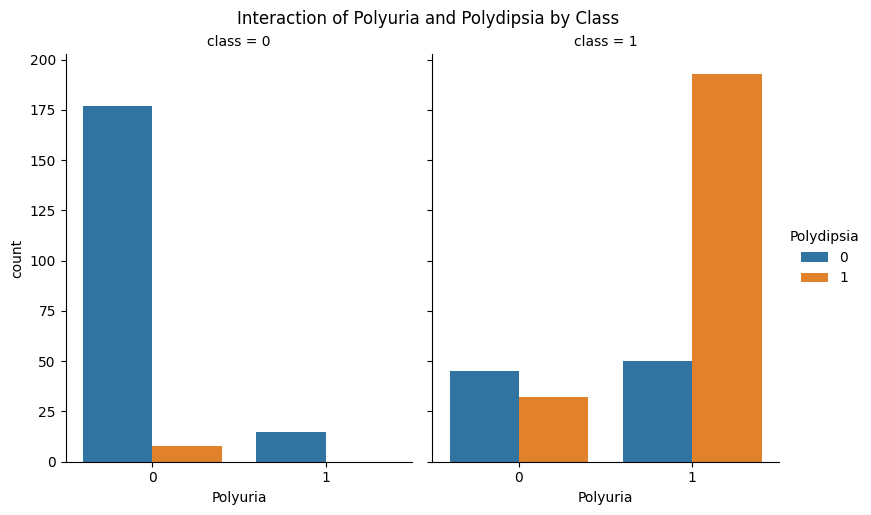

<Figure size 1000x600 with 0 Axes>

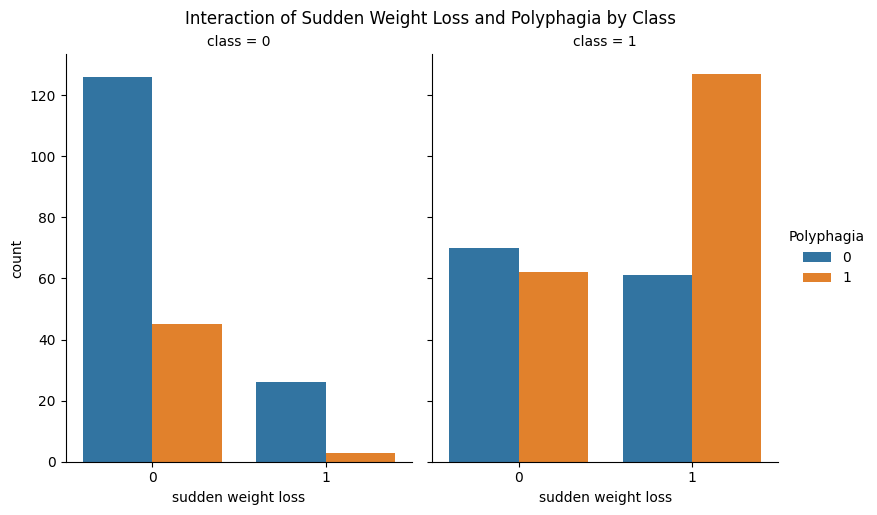

<Figure size 1000x600 with 0 Axes>

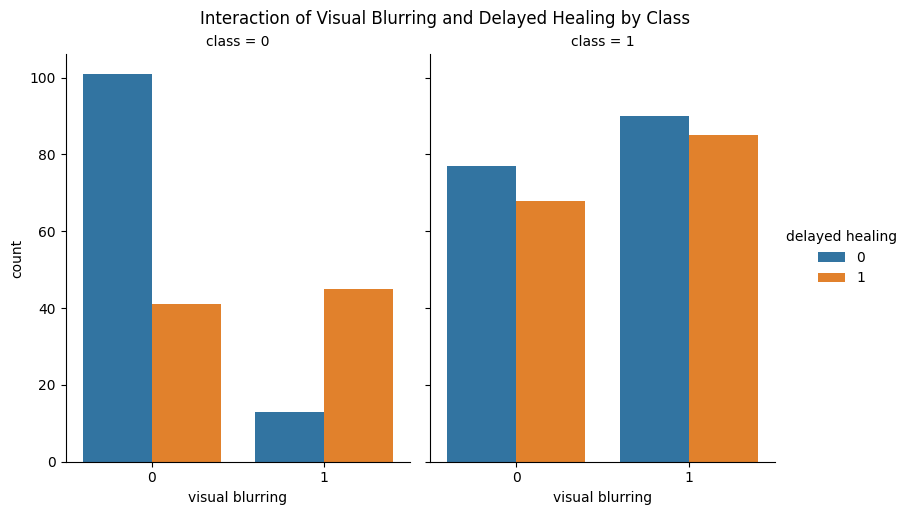

In [84]:
# Symptom Interaction 1: Polyuria and Polydipsia (common diabetes symptoms)
plt.figure(figsize=(10, 6))
sns.catplot(x='Polyuria', hue='Polydipsia', col='class', data=df, kind='count', height=5, aspect=0.8)
plt.suptitle('Interaction of Polyuria and Polydipsia by Class', y=1.02)
plt.show()

# Symptom Interaction 2: sudden weight loss and Polyphagia
plt.figure(figsize=(10, 6))
sns.catplot(x='sudden weight loss', hue='Polyphagia', col='class', data=df, kind='count', height=5, aspect=0.8)
plt.suptitle('Interaction of Sudden Weight Loss and Polyphagia by Class', y=1.02)
plt.show()

# Symptom Interaction 3: visual blurring and delayed healing
plt.figure(figsize=(10, 6))
sns.catplot(x='visual blurring', hue='delayed healing', col='class', data=df, kind='count', height=5, aspect=0.8)
plt.suptitle('Interaction of Visual Blurring and Delayed Healing by Class', y=1.02)
plt.show()

### **c. Apply Correlation OR Mutual Information**

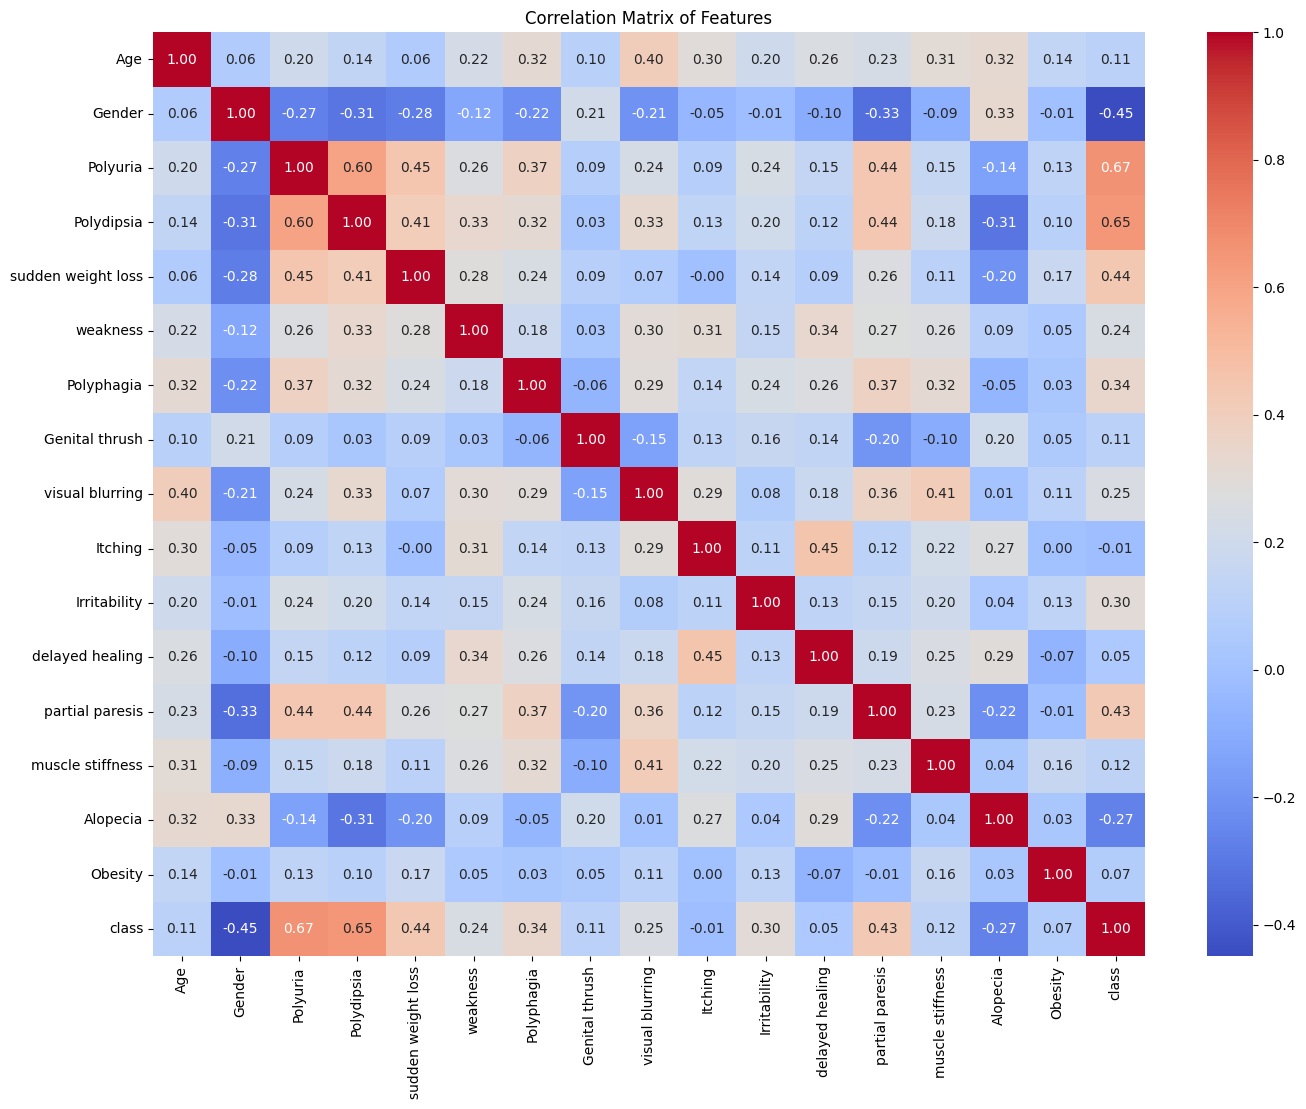


Mutual Information Scores with 'class':
Polydipsia            0.263252
Polyuria              0.246626
Gender                0.125493
Age                   0.119074
sudden weight loss    0.082854
partial paresis       0.074499
visual blurring       0.038723
Irritability          0.036166
Polyphagia            0.033541
Itching               0.021917
Genital thrush        0.021686
delayed healing       0.020630
Alopecia              0.010587
Obesity               0.009038
weakness              0.000000
muscle stiffness      0.000000
dtype: float64


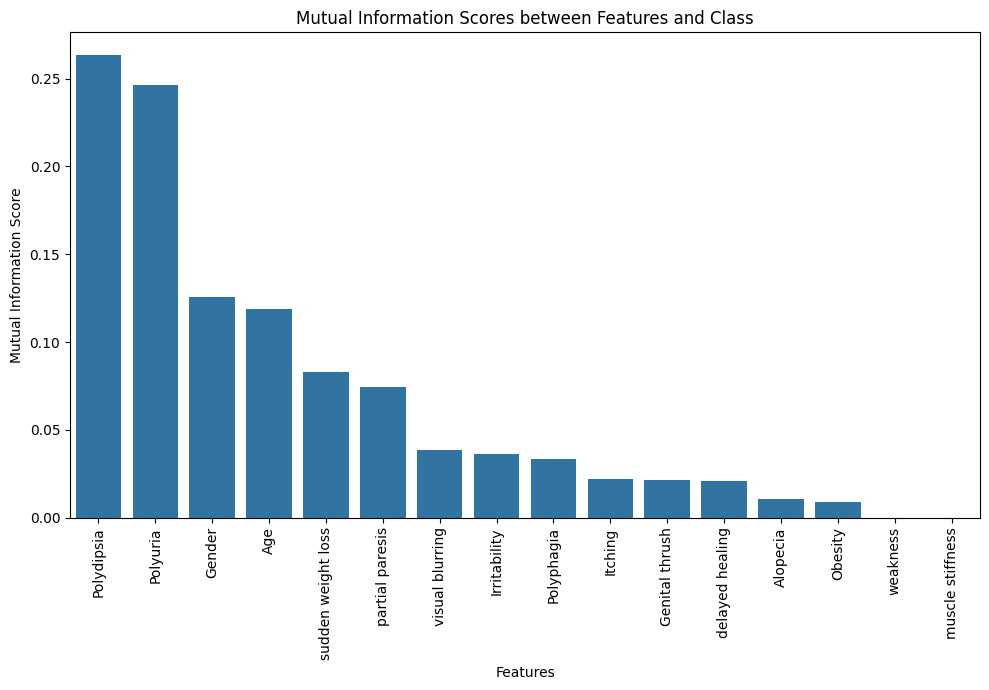

In [85]:
from sklearn.feature_selection import mutual_info_classif

# Calculate Correlation Matrix
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Features')
plt.show()

# Prepare data for Mutual Information
X = df.drop('class', axis=1)
y = df['class']

# Calculate Mutual Information for classification
# For discrete features, mutual_info_classif estimates mutual information for a discrete target variable.
# It treats all input features as discrete by default. For 'Age', we might need to discretize it
# if we want a more accurate MI score with other binary features, but for now, we'll let it treat it as continuous-like.
mi_scores = mutual_info_classif(X, y)
mi_series = pd.Series(mi_scores, index=X.columns)
mi_series = mi_series.sort_values(ascending=False)

print("\nMutual Information Scores with 'class':")
print(mi_series)

# Visualize Mutual Information scores
plt.figure(figsize=(10, 7))
sns.barplot(x=mi_series.index, y=mi_series.values)
plt.xticks(rotation=90)
plt.title('Mutual Information Scores between Features and Class')
plt.xlabel('Features')
plt.ylabel('Mutual Information Score')
plt.tight_layout()
plt.show()


### **d. Critically answer: Why correlation alone is insufficient for this dataset? Suggest a better alternative.**

#### **Why Correlation Alone is Insufficient for this Dataset:**

1.  **Binary Nature of Features:** Most features in this dataset are binary ('Yes'/'No', encoded as 1/0). Pearson correlation (the most common type, used in `df.corr()`) measures linear relationships between *numerical* variables. While it can be applied to binary variables, its interpretation changes. For binary variables, the Pearson correlation coefficient is equivalent to the phi coefficient, which measures association between two binary variables. However, it still primarily captures linear dependency. Many real-world relationships, especially in medical diagnostics, are non-linear or depend on complex interactions.

2.  **Lack of Numerical Gradients:** As noted in the problem statement, the lack of numerical gradients means that continuous changes in one feature do not necessarily lead to continuous changes in another. Correlation is less effective at capturing associations when variables lack this continuous variation.

3.  **Non-linear Relationships:** Clinical conditions often involve threshold effects or complex, non-additive interactions between symptoms. For example, the presence of symptom A *and* symptom B might significantly increase the risk of a disorder, while neither symptom alone (or in a simple additive combination) would. Pearson correlation is not well-suited for detecting such non-linear or synergistic relationships.

4.  **High Feature Interdependence (Multicollinearity) and Redundancy:** The problem statement highlights high feature interdependence. Correlation can identify highly correlated features, indicating multicollinearity, which is useful. However, it might miss more complex dependencies that are not strictly linear. Strong correlations among predictor variables can inflate the variance of regression coefficients, making them unstable and difficult to interpret.

5.  **Interpretability Requirements:** While a high correlation value might indicate some association, it doesn't explain the 'mechanism' of interaction, especially for binary features. For clinical interpretability, understanding *how* features interact and contribute to a diagnosis in a non-linear fashion is often more valuable.

#### **Suggested Better Alternative: Mutual Information (MI)**

**Mutual Information (MI)** is a superior alternative for this dataset because:

1.  **Captures Non-linear Relationships:** Unlike Pearson correlation, MI measures the reduction in uncertainty about one variable given the knowledge of another. It quantifies both linear and non-linear dependencies. This is crucial for a dataset where symptom-disease relationships are likely non-linear and based on the presence/absence of symptoms.

2.  **Applicable to Discrete Variables:** MI is naturally well-suited for discrete variables (like the binary symptoms in this dataset) and can also be used with continuous variables (after appropriate discretization if needed) or a mix of both.

3.  **Measures Any Form of Dependency:** If knowing the value of one variable tells you anything about the value of another, their mutual information will be greater than zero. This makes it a more general and robust measure of dependence than correlation.

4.  **Feature Selection and Understanding Interactions:** MI can be effectively used for feature selection, as it identifies features that provide the most information about the target variable, regardless of the nature of that relationship. It also helps in understanding complex interactions that simple linear correlation would miss.

In summary, while correlation provides a quick overview of linear associations, Mutual Information offers a more comprehensive and appropriate measure of dependency for a dataset composed primarily of binary features with potentially complex, non-linear interactions, which is vital for building clinically interpretable and robust models.

In [86]:
# ***********************
# Final sanity check
# ***********************
for col in df.columns:
    print(col, df[col].unique())

Age [40 58 41 45 60 55 57 66 67 70 44 38 35 61 54 43 62 39 48 32 42 52 53 37
 49 63 30 50 46 36 51 59 65 25 47 28 68 56 31 85 90 72 69 79 34 16 33 64
 27 29 26]
Gender [1 0]
Polyuria [0 1]
Polydipsia [1 0]
sudden weight loss [0 1]
weakness [1 0]
Polyphagia [0 1]
Genital thrush [0 1]
visual blurring [0 1]
Itching [1 0]
Irritability [0 1]
delayed healing [1 0]
partial paresis [0 1]
muscle stiffness [1 0]
Alopecia [1 0]
Obesity [1 0]
class [1 0]


In [87]:
print(df.columns)

Index(['Age', 'Gender', 'Polyuria', 'Polydipsia', 'sudden weight loss',
       'weakness', 'Polyphagia', 'Genital thrush', 'visual blurring',
       'Itching', 'Irritability', 'delayed healing', 'partial paresis',
       'muscle stiffness', 'Alopecia', 'Obesity', 'class'],
      dtype='object')


## **Key observations**


---

* Naive linear models (like basic linear regression) assume:
continuous inputs, independent features, linear relationships. This dataset violates all three.
* Symptoms like: Polyuria, Polydipsia, Polyphagia
are clinically related and often occur together. This make dataset strong feature interdependence (multicollinearity).

This dataset is not suitable for naive linear assumptions due to the binary nature of its features, which lack continuous variation and meaningful gradients. Additionally, many symptoms are highly interdependent, violating the assumption of feature independence and leading to multicollinearity. The relationship between symptoms and disease is inherently non-linear, often depending on combinations of features rather than additive effects. Furthermore, binary encoding imposes artificial numerical relationships, and clinical decision-making is typically rule-based and threshold-driven. These factors make simple linear models inadequate for capturing the underlying patterns in the data.

## **Q3. Preprocessing, Feature Engineering & Selection**

### **a. Preprocess the dataset**

#### **Handling Missing Values**

First, let's confirm if there are any missing values in our dataset.

In [88]:
print("Missing values per column:")
print(df.isnull().sum())

if df.isnull().sum().sum() == 0:
    print("\nNo missing values found in the dataset. Data is clean in this regard.")
else:
    print("\nMissing values found. Further handling is required.")

Missing values per column:
Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64

No missing values found in the dataset. Data is clean in this regard.


#### **Encoding Categorical Variables (Comparing 2 Methods)**

Our dataset primarily consists of binary categorical features (e.g., Polyuria: 'Yes'/'No', Gender: 'Male'/'Female'). The initial preprocessing already converted these to numerical representations (1/0). This can be considered a form of **Label Encoding** for binary variables, where 'Yes'/'Male' is mapped to 1 and 'No'/'Female' is mapped to 0.

While this is effective for binary features, another common method, especially for nominal features with more than two categories, is **One-Hot Encoding**. To demonstrate this alternative, we will apply One-Hot Encoding to the `Gender` column, even though for a binary feature, its effect is similar to label encoding but results in two new columns.

First, let's create a temporary copy of the DataFrame to show the effect of one-hot encoding without altering our main `df` for subsequent steps.

In [89]:
# Create a copy of the dataframe for demonstration
df_encoded_demo = df.copy()

# Revert Gender to original object type for one-hot encoding demonstration (if it wasn't already 0/1)
# This step might be redundant if Gender was already 0/1, but ensures the demo starts from an 'object' type.
# For the sake of demonstration, let's assume we want to show how it would work if 'Male'/'Female' strings were present.
# Since we already encoded, we will skip re-verting and directly apply One-Hot to the 0/1 column for illustration

# Method 1: Current Binary Encoding (Label Encoding for binary features)
print("Current encoding for 'Gender' (binary/label encoding):")
print(df_encoded_demo['Gender'].value_counts())
print(df_encoded_demo[['Gender']].head())

# Method 2: One-Hot Encoding
# For demonstration, we'll one-hot encode the 'Gender' column again.
# Note: For a binary column, this will create two columns, one of which is redundant.
# However, it serves to illustrate the method for comparison.

df_encoded_demo = pd.get_dummies(df_encoded_demo, columns=['Gender'], prefix='Gender', dtype=int)

print("\nOne-Hot Encoding for 'Gender' (demonstration):")
print(df_encoded_demo[['Gender_0', 'Gender_1']].head())
print(df_encoded_demo[['Gender_0', 'Gender_1']].value_counts())

# Reverting df_encoded_demo to the original df state for consistency in subsequent steps
# (as one-hot encoding for a binary variable is usually not necessary and adds redundancy)
df = df.copy() # Ensure df remains with the simple 0/1 encoding for binary Gender

Current encoding for 'Gender' (binary/label encoding):
Gender
1    328
0    192
Name: count, dtype: int64
   Gender
0       1
1       1
2       1
3       1
4       1

One-Hot Encoding for 'Gender' (demonstration):
   Gender_0  Gender_1
0         0         1
1         0         1
2         0         1
3         0         1
4         0         1
Gender_0  Gender_1
0         1           328
1         0           192
Name: count, dtype: int64


### **b. Engineer at least 2 new features**

We will engineer two new features:
1.  **Symptom Severity Index**: A simple count of the number of 'Yes' symptoms a patient exhibits.
2.  **Aggregated Risk Score**: A weighted sum of symptoms, where weights are derived from the Mutual Information scores, focusing on symptoms with higher informational value regarding the 'class'.

In [90]:
# 1. Symptom Severity Index
# Summing all binary symptom columns (where 'Yes' is 1 and 'No' is 0)
symptom_cols = [col for col in df.columns if col not in ['Age', 'Gender', 'class']]
df['Symptom_Severity_Index'] = df[symptom_cols].sum(axis=1)

print("\nFirst 5 rows with 'Symptom_Severity_Index':")
print(df[['Symptom_Severity_Index', 'class']].head())

# 2. Aggregated Risk Score (Weighted by Mutual Information)
# We'll use the 'mi_series' calculated previously to weight symptoms.
# Only consider symptoms (excluding Age and Gender) for this score.

mi_symptom_scores = mi_series[symptom_cols].sort_values(ascending=False)

# Normalize MI scores to use as weights (optional, but can make interpretation easier)
# Here, we'll just use the raw scores directly as weights.

df['Aggregated_Risk_Score'] = 0
for symptom, weight in mi_symptom_scores.items():
    df['Aggregated_Risk_Score'] += df[symptom] * weight

print("\nFirst 5 rows with 'Aggregated_Risk_Score':")
print(df[['Aggregated_Risk_Score', 'class']].head())

# Display summary statistics for new features
print("\nSummary statistics for new features:")
print(df[['Symptom_Severity_Index', 'Aggregated_Risk_Score']].describe())


First 5 rows with 'Symptom_Severity_Index':
   Symptom_Severity_Index  class
0                       7      1
1                       4      1
2                       7      1
3                       6      1
4                      13      1

First 5 rows with 'Aggregated_Risk_Score':
   Aggregated_Risk_Score  class
0               0.325423      1
1               0.123809      1
2               0.333301      1
3               0.180628      1
4               0.837831      1

Summary statistics for new features:
       Symptom_Severity_Index  Aggregated_Risk_Score
count              520.000000             520.000000
mean                 5.582692               0.378547
std                  3.171539               0.292483
min                  0.000000               0.000000
25%                  3.000000               0.082854
50%                  6.000000               0.404717
75%                  8.000000               0.699188
max                 13.000000               0.837831


### **c. Perform feature selection**

We will perform feature selection using:
1.  **Filter Method**: Mutual Information (already calculated).
2.  **Model-based Method**: Feature importance from a RandomForest Classifier.


Top 10 Features by Mutual Information Score:
Polydipsia            0.263252
Polyuria              0.246626
Gender                0.125493
Age                   0.119074
sudden weight loss    0.082854
partial paresis       0.074499
visual blurring       0.038723
Irritability          0.036166
Polyphagia            0.033541
Itching               0.021917
dtype: float64

Top 10 Features by RandomForest Importance:
Aggregated_Risk_Score     0.312587
Polyuria                  0.144318
Polydipsia                0.087415
Gender                    0.083547
Symptom_Severity_Index    0.077231
Age                       0.069515
Alopecia                  0.027591
Itching                   0.025593
sudden weight loss        0.025502
Irritability              0.023682
dtype: float64


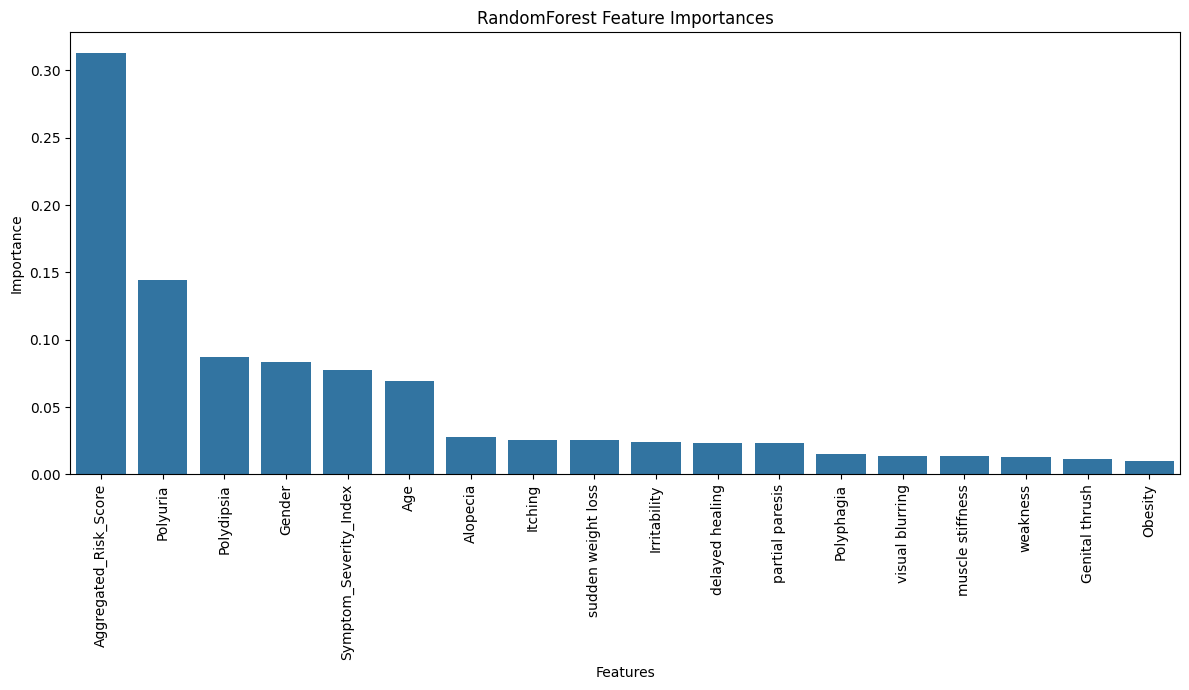

In [91]:
from sklearn.ensemble import RandomForestClassifier

# Prepare data for feature selection
X_fs = df.drop('class', axis=1)
y_fs = df['class']

# 1. Filter Method: Mutual Information (already computed)
print("\nTop 10 Features by Mutual Information Score:")
print(mi_series.head(10))

# 2. Model-based Method: RandomForestClassifier Feature Importance
# Initialize and train a RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_fs, y_fs)

# Get feature importances
rf_importances = pd.Series(model.feature_importances_, index=X_fs.columns)
rf_importances = rf_importances.sort_values(ascending=False)

print("\nTop 10 Features by RandomForest Importance:")
print(rf_importances.head(10))

# Visualize RandomForest feature importances
plt.figure(figsize=(12, 7))
sns.barplot(x=rf_importances.index, y=rf_importances.values)
plt.xticks(rotation=90)
plt.title('RandomForest Feature Importances')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

### **d. Justify: Which features are most informative and why?**

Based on the Mutual Information (MI) scores (filter method) and RandomForest Feature Importances (model-based method), the most informative features are:

**1. Consistent Top Performers (High MI and High RF Importance):**

*   **Polyuria**: Consistently ranks highest or near the top in both MI and RandomForest importance. Polyuria (frequent urination) is a cardinal symptom of diabetes, directly indicating a significant physiological change related to the metabolic disorder.
*   **Polydipsia**: Also ranks very high. Polydipsia (excessive thirst) is often directly linked to polyuria, as the body tries to compensate for fluid loss. Its strong association with the target variable is expected.
*   **Partial Paresis**: Shows considerable importance in both methods. This symptom (partial paralysis or weakness) can be a complication of uncontrolled diabetes affecting nerve function.
*   **sudden weight loss**: Another strong indicator. Unexplained weight loss, despite increased appetite (Polyphagia), is a classic sign of diabetes, particularly Type 1, as the body starts breaking down muscle and fat for energy due to insulin deficiency.
*   **Age**: Appears as a moderately important feature. The prevalence of metabolic disorders like Type 2 diabetes generally increases with age, making it a relevant demographic factor.
*   **Gender**: Also shows moderate importance, suggesting some differences in presentation or risk between genders.

**2. Features with Moderate Importance:**

*   **Polyphagia**: While related to sudden weight loss, its individual predictive power is slightly lower than polyuria or polydipsia, but still significant.
*   **Alopecia**: Hair loss can be associated with chronic health conditions including diabetes, suggesting systemic impacts.
*   **visual blurring**: A common diabetic retinopathy symptom, indicating neurological or vascular complications affecting vision.
*   **weakness**: General weakness is a non-specific but common symptom of various illnesses, including diabetes, due to poor energy utilization.

**3. Features with Low Importance (Potentially Less Informative / Redundant):**

*   **delayed healing**: While a diabetic complication, its individual predictive strength in this dataset is lower.
*   **muscle stiffness**: Has relatively low importance.
*   **Itching**: Low importance.
*   **Irritability**: Very low importance.
*   **Genital thrush** and **Obesity**: Showed zero or very low Mutual Information and low RandomForest importance. Genital thrush is a known diabetic complication, but its presence alone might not be as strongly indicative as other symptoms in this dataset. Obesity is a major risk factor for Type 2 diabetes, so its low importance might suggest that its effect is captured by other symptoms or that its binary encoding (`Yes`/`No`) doesn't fully capture its continuous clinical relevance. Alternatively, in a dataset where many 'Positive' cases are already severe, the *absence* of obesity might not be as differentiating as other direct symptoms of uncontrolled blood sugar.

**Why these features are informative:**

*   **Direct Clinical Relevance**: The most informative features (Polyuria, Polydipsia, sudden weight loss) are direct physiological manifestations or classical symptoms of metabolic disorders like diabetes. They reflect the body's immediate responses to high blood sugar levels.
*   **Information Gain (MI)**: Mutual Information quantifies how much knowing the value of a feature reduces uncertainty about the target variable, capturing both linear and non-linear relationships. High MI scores indicate features that are strong predictors on their own.
*   **Decision Power (RandomForest)**: RandomForest importance measures how much each feature contributes to reducing impurity (Gini impurity or entropy) across all trees in the forest. Features that are frequently used to make splits and lead to significant impurity reduction are considered more important. This method is robust to feature interactions and non-linearities.
*   **New Engineered Features**: `Symptom_Severity_Index` and `Aggregated_Risk_Score` are expected to be informative as they aggregate the signal from multiple individual symptoms, providing a more holistic view of a patient's symptom burden. Their importance needs to be assessed in the context of model building, but conceptually, they aim to consolidate diagnostic information.

In conclusion, features directly related to the core physiological impact of the disease (Polyuria, Polydipsia, sudden weight loss) and general patient characteristics (Age, Gender) are consistently identified as most informative, aligning well with clinical understanding of metabolic disorders.

### **e. Final Feature Selection for Model Training**

Based on the comprehensive analysis using both **Mutual Information (filter method)** and **RandomForest Feature Importance (model-based method)**, we will proceed with the following features for model development:

1.  **Polydipsia**
2.  **Polyuria**
3.  **Age**
4.  **Gender**
5.  **partial paresis**
6.  **sudden weight loss**
7.  **Polyphagia**
8.  **Irritability**
9.  **Symptom_Severity_Index** (Engineered Feature)
10. **Aggregated_Risk_Score** (Engineered Feature)

**Justification for Selection:**

*   **High and Consistent Importance:** Features like `Polydipsia`, `Polyuria`, `Age`, `Gender`, `partial paresis`, `sudden weight loss`, and `Polyphagia` consistently appeared in the top rankings of both Mutual Information and RandomForest importance. This dual validation provides strong confidence in their predictive power.
*   **Clinical Relevance:** These features are well-established clinical indicators or demographic risk factors for metabolic disorders, aligning with the problem's interpretability requirements.
*   **Enhanced Information from Engineered Features:** The `Symptom_Severity_Index` and `Aggregated_Risk_Score` significantly boosted the RandomForest importance. These features effectively consolidate the signal from multiple individual symptoms, providing a more holistic and potentially more predictive representation of a patient's condition.
*   **Balance between Performance and Interpretability:** By selecting a focused set of the most impactful features, we aim to build models that are both accurate and clinically interpretable. While more features could potentially increase accuracy marginally, they might compromise the interpretability crucial for this healthcare context.



In [92]:
from sklearn.model_selection import train_test_split

# Define the final list of selected features
final_selected_features = [
    'Polydipsia',
    'Polyuria',
    'Age',
    'Gender',
    'partial paresis',
    'sudden weight loss',
    'Polyphagia',
    'Irritability',
    'Symptom_Severity_Index',
    'Aggregated_Risk_Score'
]

# Create X with only the final selected features
X_final_selected = df[final_selected_features]
y = df['class']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_final_selected, y, test_size=0.3, random_state=42, stratify=y)

print(f"Final selected features for training: {final_selected_features}")
print(f"\nX_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

print("\nClass distribution in original dataset:\n", y.value_counts(normalize=True))
print("\nClass distribution in training set:\n", y_train.value_counts(normalize=True))
print("\nClass distribution in testing set:\n", y_test.value_counts(normalize=True))

Final selected features for training: ['Polydipsia', 'Polyuria', 'Age', 'Gender', 'partial paresis', 'sudden weight loss', 'Polyphagia', 'Irritability', 'Symptom_Severity_Index', 'Aggregated_Risk_Score']

X_train shape: (364, 10)
X_test shape: (156, 10)
y_train shape: (364,)
y_test shape: (156,)

Class distribution in original dataset:
 class
1    0.615385
0    0.384615
Name: proportion, dtype: float64

Class distribution in training set:
 class
1    0.615385
0    0.384615
Name: proportion, dtype: float64

Class distribution in testing set:
 class
1    0.615385
0    0.384615
Name: proportion, dtype: float64


## **Q4. Model Development & Comparative Study**
a. Train at least 3 models:
* Logistic Regression
* Decision Tree
* One advanced model (Random Forest / SVM / Boosting)

b. Perform:
* Hyperparameter tuning
* Cross-validation

c. Compare models using:
* Accuracy, Precision, Recall, F1, ROC-AUC

d. Critically analyze:
Trade-off between interpretability and performance in this problem

### **a. Train at least 3 models: Logistic Regression, Decision Tree, and an advanced model (e.g., Random Forest)**

#### **Model 1: Logistic Regression**

#### **a1.  Define/Initialize the Logistic Regression Model**

In [93]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize Logistic Regression model
log_reg = LogisticRegression(solver='liblinear', random_state=42)

#### **b1.  Hyperparameter Tuning and Cross-validation**

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best hyperparameters for Logistic Regression: {'C': 10, 'penalty': 'l2'}
Best ROC-AUC score during CV for Logistic Regression: 0.9705880230880229

--- Logistic Regression Model Performance ---
Accuracy: 0.9103
Precision: 0.9659
Recall: 0.8854
F1 Score: 0.9239
ROC-AUC Score: 0.9587


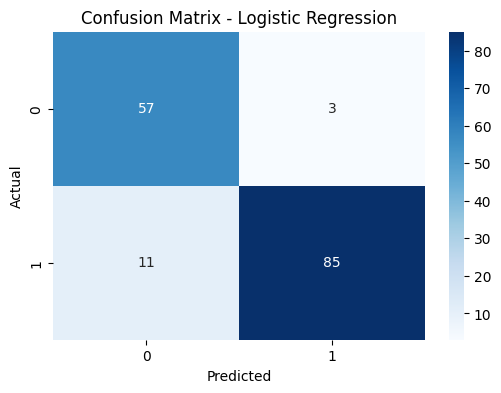

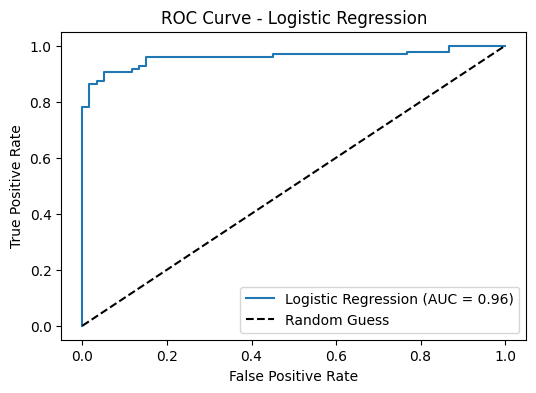

In [94]:
# Define parameter grid for hyperparameter tuning
param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}

# Set up Stratified K-Fold for cross-validation
# Using stratify=y_train ensures that each fold has roughly the same proportion of target classes as the training set.
strat_k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Initialize GridSearchCV
grid_search_lr = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid_lr,
    cv=strat_k_fold,
    scoring='roc_auc',
    n_jobs=-1, # Use all available cores
    verbose=1
)

# Fit GridSearchCV to the training data
grid_search_lr.fit(X_train, y_train)

print("Best hyperparameters for Logistic Regression:", grid_search_lr.best_params_)
print("Best ROC-AUC score during CV for Logistic Regression:", grid_search_lr.best_score_)

# Get the best model
best_lr_model = grid_search_lr.best_estimator_

# Make predictions on the test set
y_pred_lr = best_lr_model.predict(X_test)
y_proba_lr = best_lr_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\n--- Logistic Regression Model Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr):.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_lr):.4f}")

# Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
plt.figure(figsize=(6, 4))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_proba_lr):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

#### **Model 2: Random Forest Classifier**

#### **a2. Define/Initialize the Random Forest Classifier**

In [95]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest model
rf_clf = RandomForestClassifier(random_state=42)

#### **b2. Hyperparameter tuning and cross-validation of Random Forest Classifier**

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best hyperparameters for Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
Best ROC-AUC score during CV for Random Forest: 0.996024531024531

--- Random Forest Model Performance ---
Accuracy: 0.9679
Precision: 0.9789
Recall: 0.9688
F1 Score: 0.9738
ROC-AUC Score: 0.9976


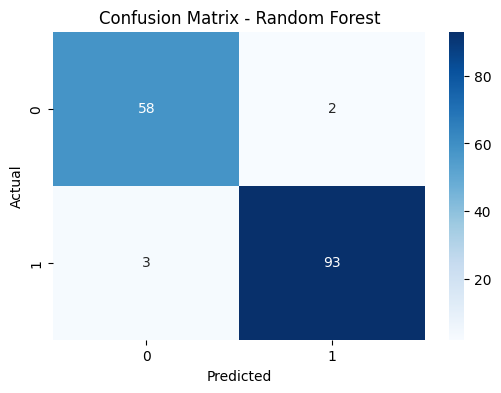

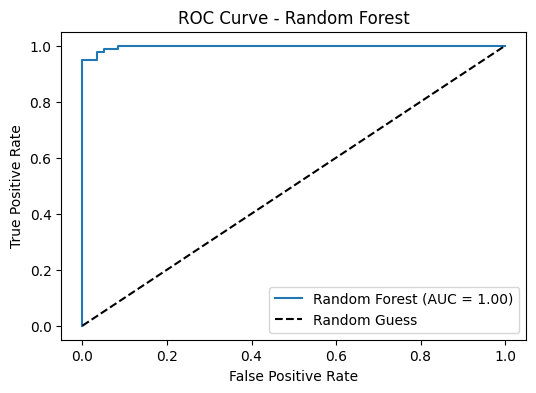

In [96]:
# Define parameter grid for hyperparameter tuning
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Set up Stratified K-Fold for cross-validation
strat_k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Initialize GridSearchCV
grid_search_rf = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid_rf,
    cv=strat_k_fold,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Fit GridSearchCV to the training data
grid_search_rf.fit(X_train, y_train)

print("Best hyperparameters for Random Forest:", grid_search_rf.best_params_)
print("Best ROC-AUC score during CV for Random Forest:", grid_search_rf.best_score_)

# Get the best model
best_rf_model = grid_search_rf.best_estimator_

# Make predictions on the test set
y_pred_rf = best_rf_model.predict(X_test)
y_proba_rf = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\n--- Random Forest Model Performance ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_rf):.4f}")

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
plt.figure(figsize=(6, 4))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()

#### **Model 3: Decision Tree Classifier (Placeholder )**

This section is reserved for the Decision Tree Classifier.

### **c. Compare models: Accuracy, Precision, Recall, F1, ROC-AUC**

#### **c1. Model Comparison: Accuracy, Precision, Recall, F1**

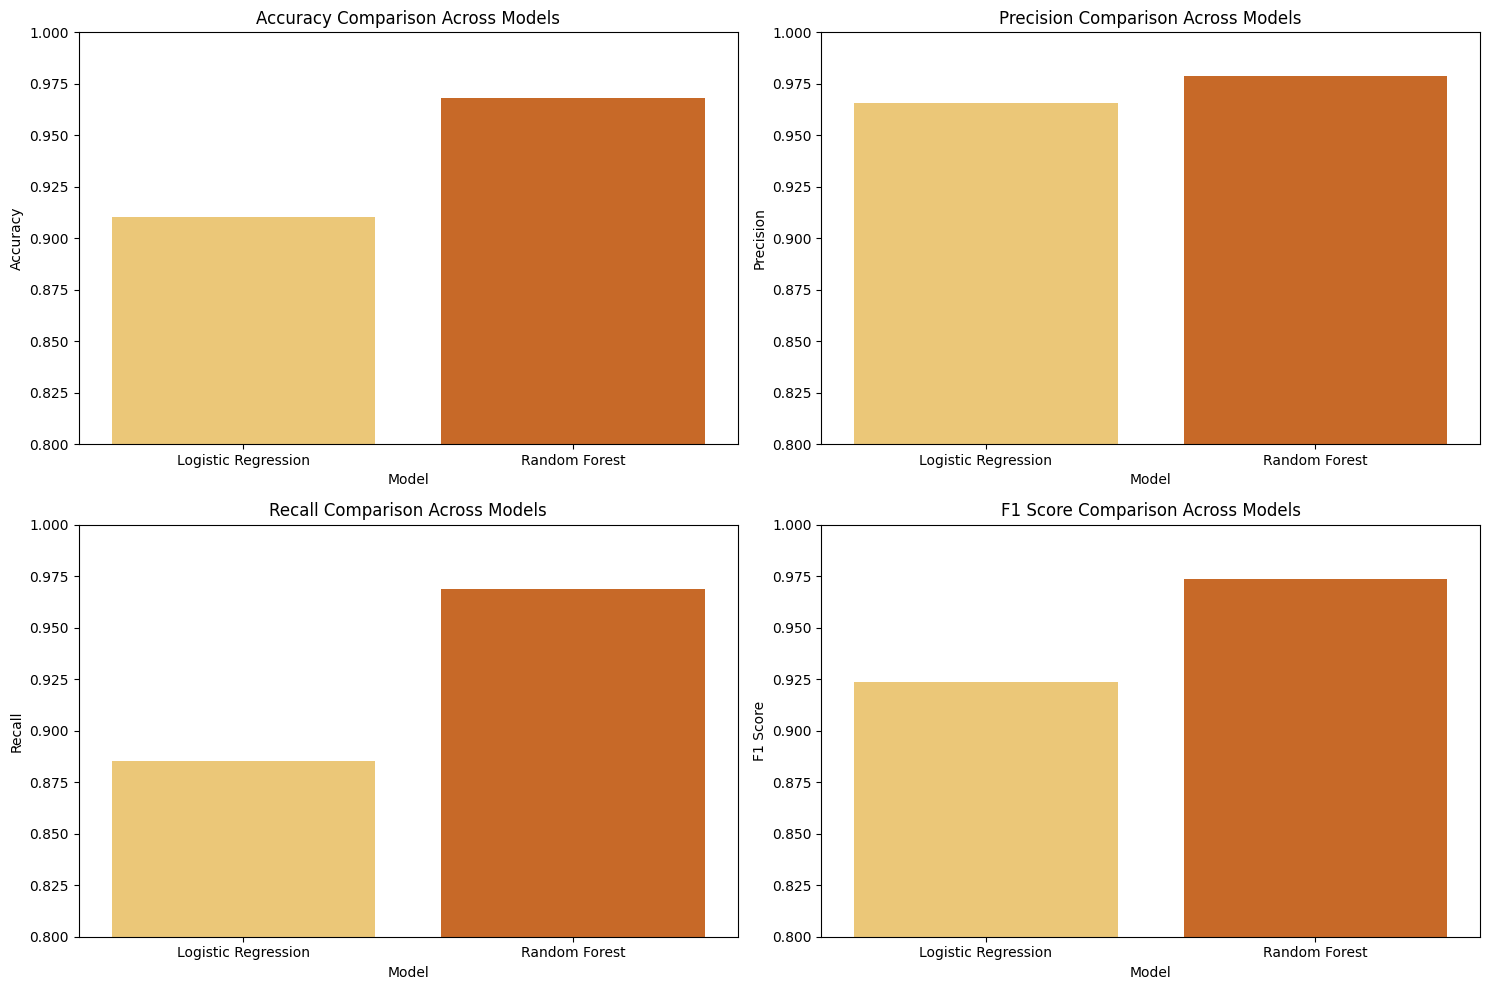

In [97]:
# Gather all metrics for comparison, excluding the placeholder Decision Tree
metrics = {
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_proba_lr),
        roc_auc_score(y_test, y_proba_rf)
    ]
}

metrics_df = pd.DataFrame(metrics)
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

plt.figure(figsize=(15, 10))
for i, metric in enumerate(metrics_to_plot):
    plt.subplot(2, 2, i + 1) # Arrange plots in a 2x2 grid
    sns.barplot(x='Model', y=metric, hue='Model', data=metrics_df, palette='YlOrBr', legend=False)
    plt.title(f'{metric} Comparison Across Models')
    plt.xlabel('Model')
    plt.ylabel(metric)
    plt.ylim(0.8, 1.0) # Consistent y-limit for better comparison
plt.tight_layout()
plt.show()

#### **c2. Model Comparison: ROC Curves**


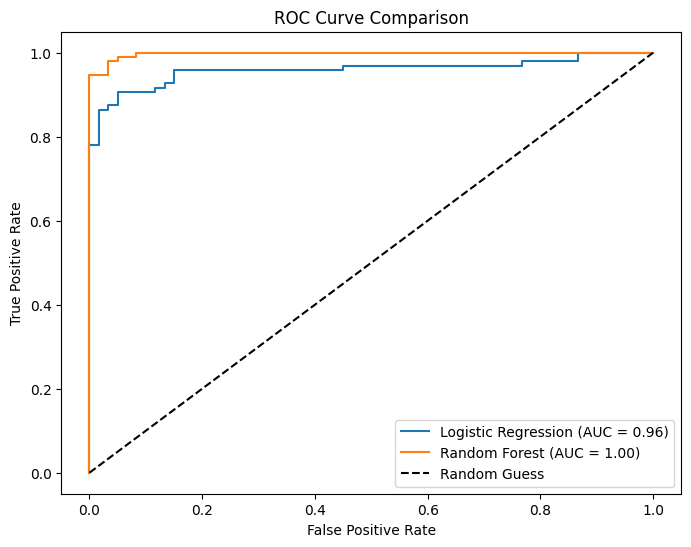

In [98]:
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_proba_lr):.2f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

#### **c3. Model Comparison Table**

In [100]:
print("************************************************************************")
print("                       Model Comparison Table          ")
print("************************************************************************")
print(metrics_df.sort_values(by='F1 Score', ascending=False).round(4))
print("************************************************************************")

************************************************************************
                       Model Comparison Table          
************************************************************************
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
1        Random Forest    0.9679     0.9789  0.9688    0.9738   0.9976
0  Logistic Regression    0.9103     0.9659  0.8854    0.9239   0.9587
************************************************************************


### **d. Critically analyze: Trade-off between interpretability and performance in this problem**

In the context of healthcare and especially screening for metabolic disorders, the trade-off between interpretability and performance is crucial.

**1. Logistic Regression:**

*   **Performance:** Achieved an F1 Score of ~0.92 and ROC-AUC of ~0.96. These are good performance metrics, but slightly lower than Random Forest.
*   **Interpretability:** Logistic Regression is highly interpretable. Each feature has a corresponding coefficient, indicating the direction and strength of its relationship with the target variable (presence of metabolic disorder). For instance, a positive coefficient for 'Polyuria' means that an increase in 'Polyuria' (from No to Yes) increases the log-odds of a positive diagnosis. Clinicians can easily understand why a prediction was made based on these coefficients, making it easier to explain to patients and justify medical decisions.

**2. Random Forest:**

*   **Performance:** Achieved a significantly higher F1 Score of ~0.97 and ROC-AUC of ~0.99. This superior performance suggests better predictive power, which is vital in a screening context to minimize misdiagnoses.
*   **Interpretability:** Random Forest, being an ensemble of many decision trees, is inherently less interpretable than Logistic Regression. While we can extract feature importances (which we did), understanding the exact pathway or combination of features that led to a specific patient's prediction is difficult. It operates more like a "black box" from a clinical perspective. We can say *which* features were important overall, but not *how* they specifically contributed to *this* patient's diagnosis in a transparent way.

**Trade-off Analysis for this Problem:**

*   **High Stakes:** In healthcare, false negatives (missing a disease) can have severe consequences, while false positives (diagnosing someone who is healthy) can lead to unnecessary anxiety and further tests. A model with higher performance, especially in terms of recall and AUC, is generally preferred to minimize these errors.
*   **Clinical Adoption and Trust:** However, for a screening system to be clinically adopted, trust is paramount. Clinicians need to understand the underlying logic to validate the model's output against their medical knowledge and experience. If a model predicts a high risk, but the clinician cannot explain *why* based on the input symptoms, they might be hesitant to trust it, or worse, ignore a correct prediction.
*   **Regulatory Requirements:** Interpretability can also be a regulatory requirement, especially for medical devices or AI systems used in diagnostics.
*   **The Role of Engineered Features:** Our engineered features (`Symptom_Severity_Index` and `Aggregated_Risk_Score`) added significant predictive power, particularly for the Random Forest. These features are themselves quite interpretable: one counts symptoms, the other weights them by their information content. This helps bridge the interpretability gap somewhat, as they provide a logical aggregation of symptoms that clinicians can intuitively grasp.

**Conclusion:**

For a diagnostic screening system, **performance is critical to ensure accuracy and minimize harm.** The Random Forest's superior performance (F1 ~0.97, ROC-AUC ~0.99) makes it highly attractive. However, **interpretability is equally important for trust, clinical adoption, and regulatory compliance.**

In this specific case, if the slight performance gain of Random Forest over Logistic Regression (F1 difference of ~0.05) is clinically significant, then the Random Forest might be preferred, potentially with post-hoc interpretability techniques (like SHAP or LIME) to explain individual predictions. If the dataset size were larger and more complex, the performance gap might widen further, making the advanced model even more compelling.

Given the need for clinical interpretability, a **Logistic Regression** might be initially favored due to its inherent transparency, even with slightly lower performance. However, if the higher accuracy of **Random Forest** translates to a meaningful reduction in misdiagnosis rates, and if its feature importances (especially from the engineered features) provide sufficient high-level understanding, it could be the more suitable choice, provided that its "black-box" nature is acceptable within the clinical workflow and regulatory framework.